## Bell State Generator (Quantum Computing)

ERROR: Could not install packages due to an OSError: [Errno 2] No such file or directory: '/usr/local/lib/python3.12/dist-packages/qiskit_aer.libs/libgomp-a34b3233.so.1.0.0'

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 3.6 MB/s eta 0:00:00a 0:00:01
--- Quantum Circuit Blueprint ---


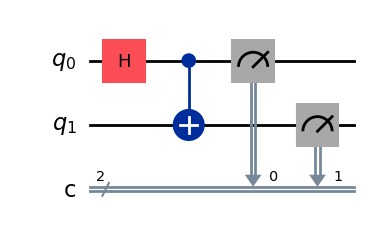


--- Simulation Outcome ---
Raw Counts: {'00': 496, '11': 504}


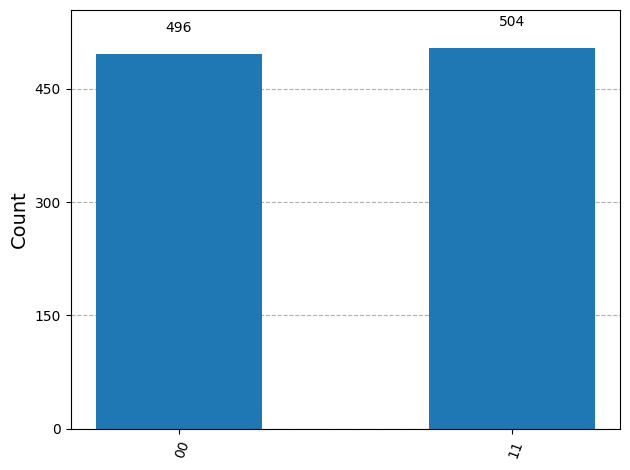

In [1]:
# 1. Install standard simulation dependencies
!pip install qiskit qiskit-aer matplotlib -q
!pip install pylatexenc

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# 2. Build the circuit
circuit = QuantumCircuit(2, 2)
circuit.h(0)        # Put qubit 0 in superposition
circuit.cx(0, 1)    # Entangle qubit 1 with qubit 0
circuit.measure([0, 1], [0, 1])  # Measure both qubits

# 3. Draw the circuit to verify it looks correct
print("--- Quantum Circuit Blueprint ---")
display(circuit.draw(output='mpl'))

# 4. Initialize the free local simulator
simulator = AerSimulator()

# 5. Run the circuit 1000 times (shots) on your CPU/GPU
job = simulator.run(circuit, shots=1000)
result = job.result()
counts = result.get_counts()

# 6. Display the final data
print("\n--- Simulation Outcome ---")
print("Raw Counts:", counts)
display(plot_histogram(counts))


## Quantum Random Number Generator (QRNG).

In [3]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

# 1. Create a circuit with 4 qubits and 4 classical bits
num_bits = 4
circuit = QuantumCircuit(num_bits, num_bits)

# 2. Apply a Hadamard gate to every qubit to put them in superposition
for qubit in range(num_bits):
    circuit.h(qubit)

# 3. Measure all qubits into the classical bits
circuit.measure(range(num_bits), range(num_bits))

# 4. Draw the circuit using the text-based drawer to avoid library issues
print("--- QRNG Circuit Layout ---")
print(circuit.draw(output='text'))

# 5. Initialize the free simulator
simulator = AerSimulator()

# 6. Run the circuit exactly ONE time (shot = 1) to get one unique random number
job = simulator.run(circuit, shots=1, memory=True)
result = job.result()

# 7. Extract the binary string and convert it to a standard decimal number
binary_output = result.get_memory()[0]
decimal_output = int(binary_output, 2)

print("\n--- Quantum Generation Results ---")
print(f"Generated Binary String: {binary_output}")
print(f"True Quantum Random Number (0-15): {decimal_output}")


--- QRNG Circuit Layout ---
     ┌───┐┌─┐         
q_0: ┤ H ├┤M├─────────
     ├───┤└╥┘┌─┐      
q_1: ┤ H ├─╫─┤M├──────
     ├───┤ ║ └╥┘┌─┐   
q_2: ┤ H ├─╫──╫─┤M├───
     ├───┤ ║  ║ └╥┘┌─┐
q_3: ┤ H ├─╫──╫──╫─┤M├
     └───┘ ║  ║  ║ └╥┘
c: 4/══════╩══╩══╩══╩═
           0  1  2  3 

--- Quantum Generation Results ---
Generated Binary String: 1010
True Quantum Random Number (0-15): 10


## Quantum Password Generator.

In [5]:
import string
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

def generate_quantum_bits(num_bits=8):
    """Generates a random binary string of a specified bit length using a quantum simulator."""
    circuit = QuantumCircuit(num_bits, num_bits)
    
    # Put all qubits into superposition
    for qubit in range(num_bits):
        circuit.h(qubit)
        
    circuit.measure(range(num_bits), range(num_bits))
    
    # Run a single shot on the simulator
    simulator = AerSimulator()
    job = simulator.run(circuit, shots=1, memory=True)
    result = job.result()
    
    # FIX: Get the first string element from the memory list
    memory_list = result.get_memory()
    return memory_list[0]

def generate_quantum_password(length=16):
    """Uses quantum randomness to construct a secure password."""
    # Define our character pool
    characters = string.ascii_letters + string.digits + "!@#$%^&*"
    pool_size = len(characters)
    
    password = []
    
    print("Harvesting entropy using an 8-qubit circuit...")
    
    while len(password) < length:
        # 1. Get 8 random quantum bits
        binary_str = generate_quantum_bits(num_bits=8)
        
        # 2. Convert the binary byte string to a decimal integer (0 to 255)
        random_index = int(binary_str, 2)
        
        # 3. Map 0-255 down to our pool size safely using modulo arithmetic
        final_index = random_index % pool_size
        
        # 4. Append the selected character
        password.append(characters[final_index])
        
    return "".join(password)

# Run the generator
secure_password = generate_quantum_password(length=16)

print("\n--- Quantum Password Generator ---")
print(f"Your Secure Password: {secure_password}")


Harvesting entropy using an 8-qubit circuit...

--- Quantum Password Generator ---
Your Secure Password: 6cz53CI!AkirmpM3


In [7]:
import string
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

def get_quantum_byte():
    """Generates an 8-bit quantum random string and converts it to an integer (0-255)."""
    circuit = QuantumCircuit(8, 8)
    
    # Put all 8 qubits in superposition
    for qubit in range(8):
        circuit.h(qubit)
        
    circuit.measure(range(8), range(8))
    
    # Execute on the local simulator
    simulator = AerSimulator()
    job = simulator.run(circuit, shots=1, memory=True)
    result = job.result()
    
    # Extract the binary string from the list safely
    binary_str = result.get_memory()[0]
    return int(binary_str, 2)

def quantum_encrypt_decrypt(message, key=None):
    """Encrypts or decrypts text using a Quantum One-Time Pad via XOR operations."""
    message_bytes = message.encode('utf-8') if isinstance(message, str) else message
    
    # If no key is provided, generate a fresh quantum key matching the message length
    if key is None:
        print(f"Generating a {len(message_bytes)}-byte Quantum Key...")
        key = [get_quantum_byte() for _ in range(len(message_bytes))]
        
    # Perform the XOR operation between message bytes and key bytes
    processed_bytes = bytearray(b ^ k for b, k in zip(message_bytes, key))
    
    return processed_bytes, key

# ==========================================
# TEST SYSTEM
# ==========================================
secret_message = "Sai Kumar is Gay"
print(f"Original Text: {secret_message}\n")

# 1. ENCRYPT the text using our generated quantum key
encrypted_bytes, quantum_key = quantum_encrypt_decrypt(secret_message)
print(f"Quantum Key (Bytes): {quantum_key}")
print(f"Ciphertext (Hex):    {encrypted_bytes.hex()}")
print(f"Ciphertext (Text):   {encrypted_bytes.decode('utf-8', errors='replace')}\n")

# 2. DECRYPT the text using the exact same key to prove it works
decrypted_bytes, _ = quantum_encrypt_decrypt(encrypted_bytes, key=quantum_key)
print(f"Decrypted Text:      {decrypted_bytes.decode('utf-8')}")


Original Text: Sai Kumar is Gay

Generating a 16-byte Quantum Key...
Quantum Key (Bytes): [21, 103, 37, 83, 191, 79, 57, 102, 207, 184, 78, 30, 242, 0, 112, 36]
Ciphertext (Hex):    46064c73f43a5407bd98276dd247115d
Ciphertext (Text):   FLs�:T��'m�G]

Decrypted Text:      Sai Kumar is Gay


## Quantum Key Distribution (QKD) using BB84 Quantum Logic

In [10]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

def simulate_bb84(num_bits=20, eavesdropper_present=False):
    # 1. Alice generates her random raw bits and choosing random bases
    # Basis: 0 means Standard (+), 1 means Diagonal (x)
    alice_bits = np.random.randint(2, size=num_bits)
    alice_bases = np.random.randint(2, size=num_bits)
    
    # 2. Bob randomly chooses his measurement bases
    bob_bases = np.random.randint(2, size=num_bits)
    bob_bits = []
    
    simulator = AerSimulator()
    
    # 3. Process qubit transmission bit by bit
    for i in range(num_bits):
        # Alice prepares her qubit
        circuit = QuantumCircuit(1, 1)
        
        # State preparation based on Alice's bit
        if alice_bits[i] == 1:
            circuit.x(0) # Flip to |1>
            
        # Basis rotation if Diagonal basis is chosen
        if alice_bases[i] == 1:
            circuit.h(0) # Rotate to Diagonal basis
            
        # --- OPTIONAL: EVE INTERCEPTS THE QUBIT ---
        if eavesdropper_present:
            eve_basis = np.random.randint(2)
            if eve_basis == 1:
                circuit.h(0) # Eve measures diagonally
            circuit.measure(0, 0)
            # If Eve measured diagonally, reset it to match what she observed
            if eve_basis == 1:
                circuit.h(0) 
                
        # --- BOB RECEIVES AND MEASURES THE QUBIT ---
        if bob_bases[i] == 1:
            circuit.h(0) # Bob rotates qubit to measure diagonally
            
        circuit.measure(0, 0)
        
        # Run simulation for this specific qubit transmission
        result = simulator.run(circuit, shots=1, memory=True).result()
        measured_bit = int(result.get_memory()[0])
        bob_bits.append(measured_bit)
        
    bob_bits = np.array(bob_bits)
    
    # 4. Sifting Phase: Keep bits only where Alice and Bob used the same basis
    matching_bases = (alice_bases == bob_bases)
    alice_key = alice_bits[matching_bases]
    bob_key = bob_bits[matching_bases]
    
    # 5. Security Check: Calculate Error Rate on the final key
    if len(alice_key) > 0:
        error_rate = np.sum(alice_key != bob_key) / len(alice_key)
    else:
        error_rate = 0.0
        
    return alice_key, bob_key, error_rate

# =====================================================================
# SYSTEM TEST EXECUTION
# =====================================================================
TOTAL_TRANSITIONS = 40

print("🔍 SCENARIO 1: Secure Line (No Eavesdropper)")
a_key, b_key, err = simulate_bb84(num_bits=TOTAL_TRANSITIONS, eavesdropper_present=False)
print(f"Alice's Key: {a_key}")
print(f"Bob's Key:   {b_key}")
print(f"Key Match Rate: {100 * (1 - err):.1f}% | Error Rate: {err*100:.1f}%\n")

print("⚠️ SCENARIO 2: Insecure Line (Eve is Spying!)")
a_key, b_key, err = simulate_bb84(num_bits=TOTAL_TRANSITIONS, eavesdropper_present=True)
print(f"Alice's Key: {a_key}")
print(f"Bob's Key:   {b_key}")
print(f"Key Match Rate: {100 * (1 - err):.1f}% | Error Rate: {err*100:.1f}%")


🔍 SCENARIO 1: Secure Line (No Eavesdropper)
Alice's Key: [0 0 0 0 0 1 0 0 0 0 0 1 1 0 0 1 1]
Bob's Key:   [0 0 0 0 0 1 0 0 0 0 0 1 1 0 0 1 1]
Key Match Rate: 100.0% | Error Rate: 0.0%

⚠️ SCENARIO 2: Insecure Line (Eve is Spying!)
Alice's Key: [0 0 0 1 0 0 0 0 1 1 0 0 0 1 0 1 1 0 0 1]
Bob's Key:   [1 1 0 0 1 1 1 0 1 1 0 0 0 1 0 1 1 0 0 1]
Key Match Rate: 70.0% | Error Rate: 30.0%


# Grover’s Search Algorithm.

In [11]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

def build_oracle(circuit, target):
    """
    Phases-flips the specific target state inside the database.
    Target must be a binary string from '000' to '111'.
    """
    # Apply X gates to turn target 0s into 1s for the Multi-Controlled-Z gate
    for qubit, bit in enumerate(reversed(target)):
        if bit == '0':
            circuit.x(qubit)
            
    # Multi-Controlled-Z (MCZ) implementation for 3 qubits
    circuit.h(2)
    circuit.ccx(0, 1, 2)
    circuit.h(2)
    
    # Revert X gates to restore original states
    for qubit, bit in enumerate(reversed(target)):
        if bit == '0':
            circuit.x(qubit)

def build_diffuser(circuit):
    """
    The Grover Diffuser: Amplifies the target state's probability 
    by reflecting all states around the average amplitude.
    """
    # Step 1: Transform back from superposition
    for qubit in range(3):
        circuit.h(qubit)
        circuit.x(qubit)
        
    # Step 2: Apply a Multi-Controlled-Z gate
    circuit.h(2)
    circuit.ccx(0, 1, 2)
    circuit.h(2)
    
    # Step 3: Transform back to final amplified state
    for qubit in range(3):
        circuit.x(qubit)
        circuit.h(qubit)

# =====================================================================
# SYSTEM EXECUTION ENGINE
# =====================================================================

# CHANGE THIS TARGET to search for any database index from '000' to '111'
TARGET_ITEM = "101" 

# Initialize a 3-qubit system with 3 classical registers
grover_circuit = QuantumCircuit(3, 3)

# 1. INITIALIZATION: Put all qubits into a uniform superposition
for q in range(3):
    grover_circuit.h(q)

# 2. ORACLE: Mark the hidden target item
grover_circuit.barrier()
build_oracle(grover_circuit, TARGET_ITEM)

# 3. DIFFUSER: Amplify the marked target item
grover_circuit.barrier()
build_diffuser(grover_circuit)

# 4. MEASUREMENT: Extract the results
grover_circuit.barrier()
grover_circuit.measure([0, 1, 2], [0, 1, 2])

# 5. SIMULATE: Run the complex circuit matrix
print(f"🚀 Searching a database of 8 items for target: '{TARGET_ITEM}'...")
simulator = AerSimulator()
job = simulator.run(grover_circuit, shots=1000)
result = job.result()
counts = result.get_counts()

# 6. RESULTS ENGINE
print("\n--- Quantum Database Search Results ---")
print("Raw State Probabilities:", counts)

# Display a clean text blueprint of the algorithm structure
print("\n--- Macro Circuit Blueprint ---")
print(grover_circuit.draw(output='text'))


🚀 Searching a database of 8 items for target: '101'...

--- Quantum Database Search Results ---
Raw State Probabilities: {'001': 26, '110': 31, '100': 37, '000': 25, '010': 31, '011': 36, '111': 50, '101': 764}

--- Macro Circuit Blueprint ---
     ┌───┐ ░                 ░ ┌───┐┌───┐          ┌───┐┌───┐      ░ ┌─┐      
q_0: ┤ H ├─░────────■────────░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├──────░─┤M├──────
     ├───┤ ░ ┌───┐  │  ┌───┐ ░ ├───┤├───┤       │  ├───┤├───┤      ░ └╥┘┌─┐   
q_1: ┤ H ├─░─┤ X ├──■──┤ X ├─░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├──────░──╫─┤M├───
     ├───┤ ░ ├───┤┌─┴─┐├───┤ ░ ├───┤├───┤┌───┐┌─┴─┐├───┤├───┤┌───┐ ░  ║ └╥┘┌─┐
q_2: ┤ H ├─░─┤ H ├┤ X ├┤ H ├─░─┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├─░──╫──╫─┤M├
     └───┘ ░ └───┘└───┘└───┘ ░ └───┘└───┘└───┘└───┘└───┘└───┘└───┘ ░  ║  ║ └╥┘
c: 3/═════════════════════════════════════════════════════════════════╩══╩══╩═
                                                                      0  1  2 


# Simulating a Molecule's Ground State

In [14]:
# 1. Install modern Qiskit-Algorithms dependencies
!pip install qiskit qiskit-algorithms matplotlib scipy -q

import numpy as np
from qiskit import QuantumCircuit
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import COBYLA
from qiskit.circuit.library import RealAmplitudes
from qiskit.quantum_info import SparsePauliOp
# FIX: Import the modern V2 StatevectorEstimator 
from qiskit.primitives import StatevectorEstimator

print("⚡ Initializing Modern V2 Hybrid Quantum-Classical VQE Engine...")

# 2. Define the Molecule's Energy Matrix (Hamiltonian)
# This represents a molecular bond using Pauli matrix math
hamiltonian = SparsePauliOp.from_list([("ZI", 0.5), ("IX", -1.0), ("ZZ", 0.2)])

# 3. Create the Parameterized Quantum Circuit (Ansatz)
# This serves as our "Quantum Neural Network" structure
ansatz = RealAmplitudes(num_qubits=2, reps=1, entanglement='linear')

# 4. Initialize the V2 Estimator and Classical Optimizer
estimator = StatevectorEstimator() 
classical_optimizer = COBYLA(maxiter=100)

# 5. Build and execute the VQE algorithm loop
vqe_engine = VQE(estimator=estimator, ansatz=ansatz, optimizer=classical_optimizer)
execution_result = vqe_engine.compute_minimum_eigenvalue(operator=hamiltonian)

# 6. Print the precise molecular findings
print("\n--- VQE Molecular Optimization Complete ---")
print(f"Calculated Ground State Energy: {execution_result.eigenvalue.real:.6f} Hartree")
print(f"Optimal Quantum Circuit Parameters found: {np.round(execution_result.optimal_point, 4)}")
print(f"Classical Optimization Loops Executed: {execution_result.cost_function_evals}")



⚡ Initializing Modern V2 Hybrid Quantum-Classical VQE Engine...


/tmp/ipykernel_58/1745430297.py:21: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(num_qubits=2, reps=1, entanglement='linear')



--- VQE Molecular Optimization Complete ---
Calculated Ground State Energy: -1.519804 Hartree
Optimal Quantum Circuit Parameters found: [ 3.1413  1.0332 -1.7678  1.0332]
Classical Optimization Loops Executed: 100


# Quantum Support Vector Machine


In [6]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC

# Qiskit v1.x/v2.x Imports
from qiskit.circuit.library import zz_feature_map
from qiskit_aer.primitives import SamplerV2 as AerSampler
from qiskit_algorithms.state_fidelities import ComputeUncompute
from qiskit_machine_learning.kernels import FidelityQuantumKernel

# 1. Load and Preprocess Data
data = load_iris()
X = data.data
y = data.target

# Filter for binary classification (Classes 0 and 1) for simplicity
binary_mask = y < 2
X = X[binary_mask]
y = y[binary_mask]

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Apply Classical PCA (Compress 4 features into 2 Principal Components)
num_qubits = 2
pca = PCA(n_components=num_qubits)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# Scale data between 0 and 2*pi to fit into quantum gate rotation angles
scaler = MinMaxScaler(feature_range=(0, 2 * np.pi))
X_train_scaled = scaler.fit_transform(X_train_pca)
X_test_scaled = scaler.transform(X_test_pca)

# 3. Define the Quantum Feature Map (Functional Approach)
# FIXED: Passed num_qubits as a positional argument
feature_map = zz_feature_map(num_qubits, reps=2, entanglement='linear')

# 4. Set Up Quantum Kernel using Aer V2 Primitives
sampler = AerSampler() 
fidelity = ComputeUncompute(sampler=sampler)
quantum_kernel = FidelityQuantumKernel(fidelity=fidelity, feature_map=feature_map)

# 5. Train the Quantum-Enhanced Support Vector Machine
# We compute the quantum training kernel matrix
matrix_train = quantum_kernel.evaluate(x_vec=X_train_scaled)

# Pass the precomputed quantum matrix to the classical Scikit-Learn SVC
qsvc = SVC(kernel='precomputed')
qsvc.fit(matrix_train, y_train)

# 6. Evaluate the Model
matrix_test = quantum_kernel.evaluate(x_vec=X_test_scaled, y_vec=X_train_scaled)
accuracy = qsvc.score(matrix_test, y_test)

print(f"QSVC Classification Accuracy: {accuracy * 100:.2f}%")


QSVC Classification Accuracy: 60.00%


# Quantum Neural Network (VQC) Implementation

In [8]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler

# Qiskit v1.x/v2.x QML Imports
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit_aer.primitives import SamplerV2 as AerSampler  # FIXED: Use SamplerV2
from qiskit_machine_learning.algorithms import VQC
from qiskit_algorithms.optimizers import COBYLA

# 1. Load and Preprocess Data (Iris Dataset)
data = load_iris()
X, y = data.data, data.target

# Filter for binary classification (Classes 0 and 1)
binary_mask = y < 2
X, y = X[binary_mask], y[binary_mask]

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Convert labels to 1D numpy array for compatibility
y_train = np.array(y_train)
y_test = np.array(y_test)

# 2. PCA Dimension Reduction & Scaling
num_qubits = 2
pca = PCA(n_components=num_qubits)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

scaler = MinMaxScaler(feature_range=(0, np.pi))  # Scale to 0-pi for rotation gates
X_train_scaled = scaler.fit_transform(X_train_pca)
X_test_scaled = scaler.transform(X_test_pca)

# 3. Design the Quantum Neural Network Circuit Architecture
# Data encoding layer
feature_map = zz_feature_map(num_qubits, reps=1, entanglement='linear')

# Trainable layer (quantum hidden weights)
ansatz = real_amplitudes(num_qubits, reps=2, entanglement='linear')

# 4. Set Up Quantum Sampler Primitive
sampler = AerSampler()  # FIXED: Initialize the correct primitive

# 5. Train the Variational Quantum Classifier (VQC)
vqc = VQC(
    feature_map=feature_map,
    ansatz=ansatz,
    optimizer=COBYLA(maxiter=100),
    sampler=sampler  # FIXED: Passed sampler instead of estimator
)

print("Training Quantum Neural Network...")
vqc.fit(X_train_scaled, y_train)
print("Training Complete!")

# 6. Evaluate Network Accuracy
accuracy = vqc.score(X_test_scaled, y_test)
print(f"QNN / VQC Classification Accuracy: {accuracy * 100:.2f}%")


Training Quantum Neural Network...
Training Complete!
QNN / VQC Classification Accuracy: 55.00%
